Exploration of untrained predefined CNN architectures (resnet, efficientnet) and their performance on this dataset.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import os

In [2]:
torch.cuda.is_available()


True

In [3]:
filepath = 'processed_dataset.pt'
loaded_data = torch.load(filepath)
loaded_features = loaded_data['features']
loaded_labels = loaded_data['labels']
loaded_labels = loaded_labels[:,0]

In [7]:
class XrayImageDataset(torch.utils.data.Dataset):
    def __init__(self, data, labels):
        self.data = data
        self.labels = labels

    def __len__(self):
        return self.data.shape[0]

    def __getitem__(self, idx):
        return self.data[idx].unsqueeze(0), self.labels[idx]

wholedataset = XrayImageDataset(loaded_features, loaded_labels)

train_len = int(len(wholedataset) * 0.8)  # 80% for training
val_len = int(len(wholedataset) * 0.1)    # 10% for validation
test_len = len(wholedataset) - train_len - val_len # Remaining 10% for testing

train_dataset, val_dataset, test_dataset = torch.utils.data.random_split(wholedataset, [train_len, val_len, test_len])

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=True)

In [9]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()

        outputs = model(x)
        loss = criterion(outputs, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

def validate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            loss = criterion(outputs, y)

            total_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

    acc = correct / total
    return total_loss / len(loader), acc

In [21]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = torchvision.models.resnet18()
# Replace the last layer with a custom one to output the correct number of classes
model.fc = nn.Linear(model.fc.in_features, 22)
model.conv1 = nn.Conv2d(
    in_channels=1,
    out_channels=64,
    kernel_size=7,
    stride=2,
    padding=3,
    bias=False
)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [22]:
import time
num_epochs = 10
train_losses = []
train_accs = []
val_losses = []
val_accs = []
for epoch in range(num_epochs):
    start = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    train_loss, train_acc = validate(model, train_loader, criterion, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}")
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    print(f"Time elapsed: {time.time() - start:.2f}s")

Epoch 1
Train Loss: 1.7245, Train Acc: 0.5518
Val Loss: 1.8373, Val Acc: 0.5376
Time elapsed: 4.84s
Epoch 2
Train Loss: 1.2390, Train Acc: 0.6496
Val Loss: 1.3984, Val Acc: 0.6185
Time elapsed: 4.77s
Epoch 3
Train Loss: 1.1589, Train Acc: 0.6511
Val Loss: 1.3916, Val Acc: 0.5838
Time elapsed: 4.82s
Epoch 4
Train Loss: 1.3889, Train Acc: 0.5935
Val Loss: 1.7158, Val Acc: 0.5202
Time elapsed: 4.68s
Epoch 5
Train Loss: 0.8937, Train Acc: 0.7180
Val Loss: 1.2256, Val Acc: 0.6243
Time elapsed: 4.63s
Epoch 6
Train Loss: 0.5268, Train Acc: 0.8388
Val Loss: 0.8800, Val Acc: 0.7803
Time elapsed: 4.52s
Epoch 7
Train Loss: 0.7747, Train Acc: 0.7734
Val Loss: 1.1637, Val Acc: 0.7225
Time elapsed: 4.51s
Epoch 8
Train Loss: 0.6137, Train Acc: 0.8014
Val Loss: 0.9895, Val Acc: 0.7052
Time elapsed: 4.60s
Epoch 9
Train Loss: 0.4510, Train Acc: 0.8619
Val Loss: 0.7902, Val Acc: 0.7746
Time elapsed: 4.61s
Epoch 10
Train Loss: 0.5343, Train Acc: 0.8381
Val Loss: 0.9857, Val Acc: 0.7572
Time elapsed: 4.64s

In [23]:
torch.save(model.state_dict(), '10_resnet18.pth')

In [24]:
num_epochs = 10

for epoch in range(num_epochs):
    start = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    train_loss, train_acc = validate(model, train_loader, criterion, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    
    print(f"Epoch {10+epoch+1}")
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    print(f"Time elapsed: {time.time() - start:.2f}s")

Epoch 11
Train Loss: 0.4663, Train Acc: 0.8719
Val Loss: 1.0311, Val Acc: 0.7977
Time elapsed: 4.65s
Epoch 12
Train Loss: 1.3345, Train Acc: 0.7252
Val Loss: 1.8855, Val Acc: 0.6185
Time elapsed: 4.78s
Epoch 13
Train Loss: 0.2852, Train Acc: 0.9036
Val Loss: 0.7820, Val Acc: 0.8035
Time elapsed: 4.66s
Epoch 14
Train Loss: 0.1786, Train Acc: 0.9496
Val Loss: 0.7394, Val Acc: 0.8150
Time elapsed: 4.61s
Epoch 15
Train Loss: 0.3114, Train Acc: 0.8928
Val Loss: 1.1467, Val Acc: 0.7688
Time elapsed: 4.67s
Epoch 16
Train Loss: 0.2013, Train Acc: 0.9338
Val Loss: 1.0188, Val Acc: 0.7399
Time elapsed: 4.60s
Epoch 17
Train Loss: 0.1543, Train Acc: 0.9468
Val Loss: 1.1454, Val Acc: 0.7746
Time elapsed: 4.62s
Epoch 18
Train Loss: 0.1272, Train Acc: 0.9590
Val Loss: 1.0187, Val Acc: 0.7861
Time elapsed: 4.55s
Epoch 19
Train Loss: 0.0582, Train Acc: 0.9813
Val Loss: 1.0690, Val Acc: 0.8208
Time elapsed: 4.55s
Epoch 20
Train Loss: 0.0755, Train Acc: 0.9777
Val Loss: 0.8068, Val Acc: 0.8324
Time elaps

In [25]:
torch.save(model.state_dict(), '20_RESNET18.pth')

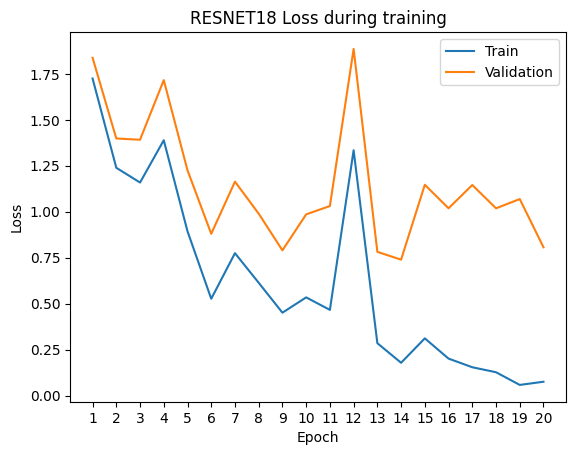

In [39]:
plt.plot(range(1,21),train_losses)
plt.plot(range(1,21), val_losses)
plt.legend(['Train','Validation'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(range(1,21))
plt.title("RESNET18 Loss during training")
plt.savefig("Resnet18Losses.png")

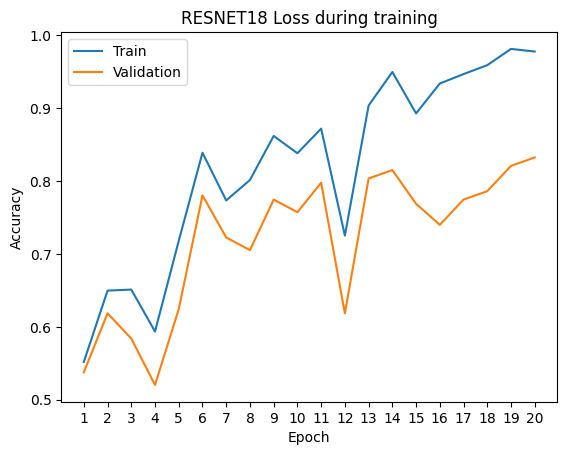

In [38]:
plt.plot(range(1,21),train_accs)
plt.plot(range(1,21), val_accs)
plt.legend(['Train','Validation'])
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.xticks(range(1,21))
plt.title("RESNET18 Loss during training")
plt.savefig("Resnet18Accuracies.png")

In [44]:
model = torchvision.models.efficientnet_b0()
model

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [50]:
model = torchvision.models.efficientnet_b0()
# (features): Sequential(
#     (0): Conv2dNormActivation(
#       (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
#       (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
#       (2): SiLU(inplace=True)
#     )
model.features[0][0] = nn.Conv2d(1,32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)

# Replace the last layer with a custom one to output the correct number of classes
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 22)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [51]:
model

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [52]:
num_epochs = 20
train_losses = []
train_accs = []
val_losses = []
val_accs = []

for epoch in range(num_epochs):
    start = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    train_loss, train_acc = validate(model, train_loader, criterion, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}")
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    print(f"Time elapsed: {time.time() - start:.2f}s")

Epoch 1
Train Loss: 2.1712, Train Acc: 0.4173
Val Loss: 2.1921, Val Acc: 0.4104
Time elapsed: 11.72s
Epoch 2
Train Loss: 1.8870, Train Acc: 0.5813
Val Loss: 2.5912, Val Acc: 0.5376
Time elapsed: 11.40s
Epoch 3
Train Loss: 1.4323, Train Acc: 0.5791
Val Loss: 1.6777, Val Acc: 0.5260
Time elapsed: 11.06s
Epoch 4
Train Loss: 1.3824, Train Acc: 0.5151
Val Loss: 1.4232, Val Acc: 0.5434
Time elapsed: 11.06s
Epoch 5
Train Loss: 1.0917, Train Acc: 0.6734
Val Loss: 1.5258, Val Acc: 0.5838
Time elapsed: 11.39s
Epoch 6
Train Loss: 0.9190, Train Acc: 0.7137
Val Loss: 1.1138, Val Acc: 0.6936
Time elapsed: 11.20s
Epoch 7
Train Loss: 0.8339, Train Acc: 0.7396
Val Loss: 1.0397, Val Acc: 0.6821
Time elapsed: 11.01s
Epoch 8
Train Loss: 0.8295, Train Acc: 0.7367
Val Loss: 1.2181, Val Acc: 0.6590
Time elapsed: 11.08s
Epoch 9
Train Loss: 0.7944, Train Acc: 0.7532
Val Loss: 1.2766, Val Acc: 0.6821
Time elapsed: 11.28s
Epoch 10
Train Loss: 0.6559, Train Acc: 0.8022
Val Loss: 1.0982, Val Acc: 0.6879
Time elaps

TypeError: save() missing 1 required positional argument: 'f'

In [53]:
torch.save(model.state_dict(), "11_efficientnet.pth")

In [54]:
num_epochs = 9

for epoch in range(num_epochs):
    start = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    train_loss, train_acc = validate(model, train_loader, criterion, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f"Epoch {11+epoch+1}")
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    print(f"Time elapsed: {time.time() - start:.2f}s")
torch.save(model.state_dict(), "20_efficientnet.pth")

Epoch 12
Train Loss: 0.5031, Train Acc: 0.8446
Val Loss: 0.9015, Val Acc: 0.7803
Time elapsed: 11.34s
Epoch 13
Train Loss: 0.3855, Train Acc: 0.8799
Val Loss: 0.9078, Val Acc: 0.7572
Time elapsed: 11.30s
Epoch 14
Train Loss: 0.4120, Train Acc: 0.8712
Val Loss: 0.8415, Val Acc: 0.7861
Time elapsed: 11.11s
Epoch 15
Train Loss: 0.3686, Train Acc: 0.8791
Val Loss: 0.9061, Val Acc: 0.8035
Time elapsed: 11.13s
Epoch 16
Train Loss: 0.3834, Train Acc: 0.8842
Val Loss: 0.9128, Val Acc: 0.8035
Time elapsed: 11.17s
Epoch 17
Train Loss: 0.3155, Train Acc: 0.9043
Val Loss: 0.8302, Val Acc: 0.7977
Time elapsed: 11.16s
Epoch 18
Train Loss: 0.2481, Train Acc: 0.9180
Val Loss: 0.7546, Val Acc: 0.8092
Time elapsed: 11.14s
Epoch 19
Train Loss: 0.1799, Train Acc: 0.9432
Val Loss: 0.8198, Val Acc: 0.8497
Time elapsed: 11.17s
Epoch 20
Train Loss: 0.1493, Train Acc: 0.9583
Val Loss: 0.7757, Val Acc: 0.8208
Time elapsed: 11.29s


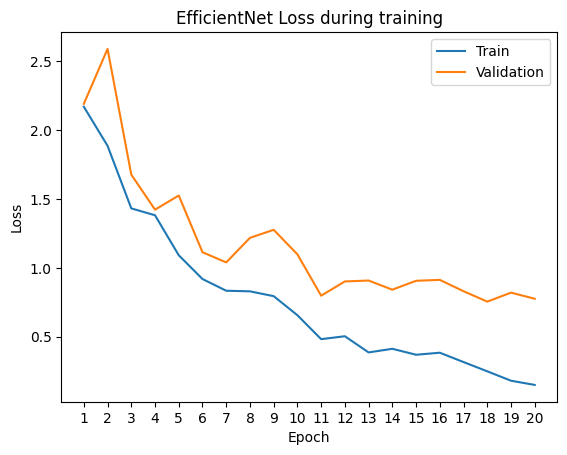

In [55]:
plt.plot(range(1,21),train_losses)
plt.plot(range(1,21), val_losses)
plt.legend(['Train','Validation'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(range(1,21))
plt.title("EfficientNet Loss during training")
plt.savefig("EfficientnetLosses.png")

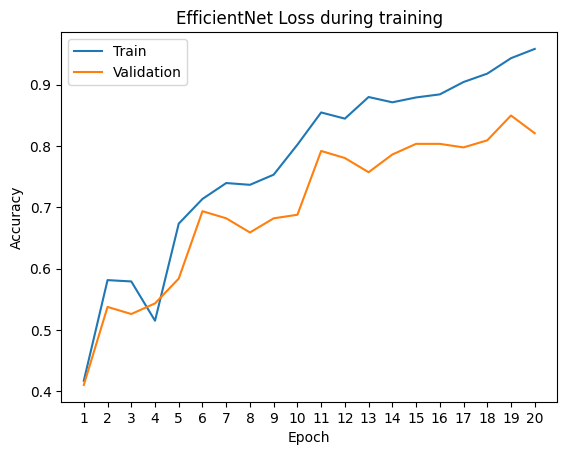

In [56]:
plt.plot(range(1,21),train_accs)
plt.plot(range(1,21), val_accs)
plt.legend(['Train','Validation'])
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.xticks(range(1,21))
plt.title("EfficientNet Loss during training")
plt.savefig("EfficientnetAccuracies.png")